# How FinBERT (a BERT model trained on financial text) processes

let’s trace the sentence: `"The bank raised interest rates".`

Because **FinBERT** specializes in finance, it must recognize that `"bank"`here refers to a central or commercial bank (not a riverbank), using clues from "raised", "interest", and "rates".

### Stage-by-Stage Breakdown in FinBERT

| Stage | Component in Diagram | What Happens Inside FinBERT (`ProsusAI/finbert`) | Tensor Shape (1 Head) |
| :--- | :--- | :--- | :--- |
| **1. Tokenization** | `[CLS]` ... `[SEP]` | Splits text into tokens: `['[CLS]', 'the', 'bank', 'raised', 'interest', 'rates', '[SEP]']` (7 tokens). | `(7,)` token IDs |
| **2. Embedding ($X$)** | Yellow Vector $X$ | Converts the token `"bank"` into a 768-number vector representing its base meaning + position. | `(1, 768)` |
| **3. Linear Transform** | Cyan, Pink, Blue Boxes | Multiplies $X$ by three learned weight matrices ($W_Q, W_K, W_V$ of size 768 × 64 per head). | `768 × 64` weights |
| **4. Q, K, V Vectors** | Cyan, Pink, Blue Outputs | Produces three distinct 64-number vectors for `"bank"`: Query, Key, and Value. | `(1, 64)` each |
| **5. Attention Match** | (Next Step) | Compares `"bank"`'s Query against every word's Key to compute attention weights. | `(7,)` scores |


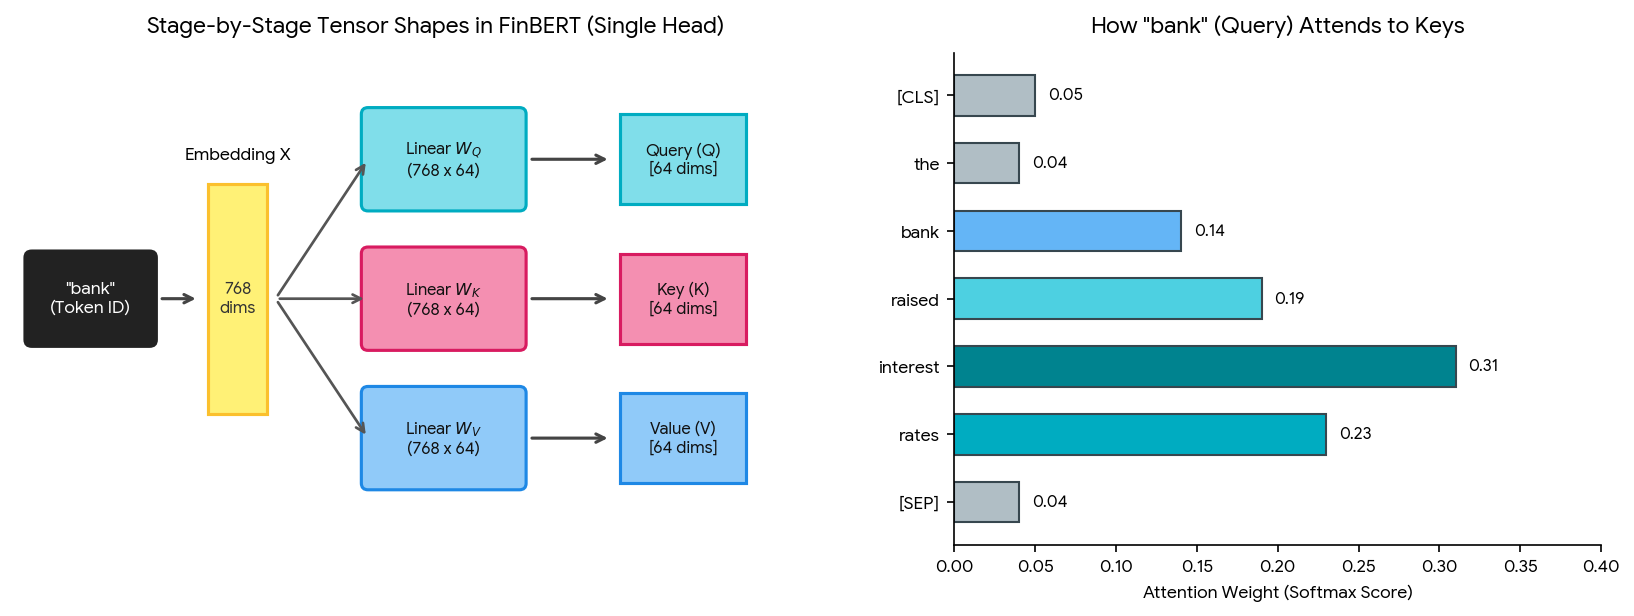

---
* **Left visual:** Shows how the 768-dimensional embedding vector $X$ for `"bank"` splits into three separate 64-dimensional vectors (Query, Key, and Value) inside a single attention head.
* **Right visual:** Shows why this matters—when `"bank"`'s Query checks the Keys of neighboring words, it gives the highest attention scores to `"interest"` (`0.31`) and `"rates"` (`0.23`), confirming its financial meaning.
---
---

In [7]:
from IPython.display import IFrame

# Displays the interactive HTML page inside your notebook output cell
IFrame(src="finbert_qkv_heads.html", width="100%", height=820)


In [15]:
IFrame(src="finbert_word_pictorial_qkv_all_heads.html", width="100%", height=820)



In [1]:
from huggingface_hub import login

# Paste your token when prompted (get it from huggingface.co/settings/tokens)
login()


In [3]:
!pip install transformers

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/13.6 MB ? eta -:--:--
   ------ --------------------------------- 2.1/13.6 MB 12.1 MB/s eta 0:00:01
   ------------ --------------------------- 4.2/13.6 MB 11.6 MB/s eta 0:00:01
   ------------------ --------------------- 6.3/13.6 MB 11.4 MB/s eta 0:00:01
   ------------------------- -------------- 8.7/13.6 MB 11.2 MB/s eta 0:00:01
   -------------------------------- ------- 11.0/13.6 MB 11.3 MB/s eta 0:00:01
   ---------------------------------------  13.4/13.6 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------- 13.6/13.6 MB 10.4 MB/s  0:00:01
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   -------------------------------- ------- 2.4/2.9 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 2.9/2.9 MB 10.6 MB/s  0:00:00

   ------------- -------------------------- 1/3 [tokenizers]
   ------------- -------

In [4]:
import torch
from transformers import AutoTokenizer, AutoModel

# 1. Load pre-trained FinBERT model and tokenizer
model_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name, output_attentions=True)
model.eval()

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

C:\Users\vmanj\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\vmanj\.cache\huggingface\hub\models--ProsusAI--finbert. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

C:\Users\vmanj\AppData\Roaming\Python\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\vmanj\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ProsusAI/finbert
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [5]:

# 2. Tokenize the financial sentence
sentence = "The bank raised interest rates"
inputs = tokenizer(sentence, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
print("Tokens:", tokens)


Tokens: ['[CLS]', 'the', 'bank', 'raised', 'interest', 'rates', '[SEP]']


In [6]:

with torch.no_grad():
  # Stage 1 & 2: Get Input Embedding Vector (X)
  # Shape: [batch_size=1, seq_len=7, hidden_size=768]
  X = model.embeddings(inputs["input_ids"])
  print(f"\n[Stage 2] Embedding Vector X shape: {X.shape}")

  # Isolate the embedding vector X specifically for the word "bank" (index 2)
  bank_idx = tokens.index("bank")
  X_bank = X[:, bank_idx, :]  # Shape: [1, 768]

  # Stage 3 & 4: Linear Transformations in Layer 0 Attention
  attention_layer = model.encoder.layer[0].attention.self

  # Pass X through the 3 linear layers (Cyan, Pink, Blue boxes in diagram)
  Q_all = attention_layer.query(X)  # [1, 7, 768]
  K_all = attention_layer.key(X)  # [1, 7, 768]
  V_all = attention_layer.value(X)  # [1, 7, 768]

  # FinBERT splits 768 dims into 12 attention heads of 64 dims each
  # Let's extract Head 0's Q, K, V vectors for the word "bank"
  Q_bank_head0 = Q_all[0, bank_idx, :64]
  K_bank_head0 = K_all[0, bank_idx, :64]
  V_bank_head0 = V_all[0, bank_idx, :64]

  print(f"[Stage 4] 'bank' Query (Head 0) shape: {Q_bank_head0.shape}")
  print(f"[Stage 4] 'bank' Key   (Head 0) shape: {K_bank_head0.shape}")
  print(f"[Stage 4] 'bank' Value (Head 0) shape: {V_bank_head0.shape}")
  print(f"\nFirst 5 values of 'bank' Query vector:\n{Q_bank_head0[:5].numpy()}")

  # Stage 5: Compute Attention Scores (Query of "bank" dot Keys of all words)
  K_all_head0 = K_all[0, :, :64]  # Keys for all 7 tokens in Head 0
  raw_scores = torch.matmul(Q_bank_head0, K_all_head0.T) / (64**0.5)
  attention_weights = torch.softmax(raw_scores, dim=-1)

  print("\n[Stage 5] Attention weights from 'bank' to every token (Head 0):")
  for tok, score in zip(tokens, attention_weights):
    print(f"  {tok:<10}: {score.item():.4f}")



[Stage 2] Embedding Vector X shape: torch.Size([1, 7, 768])
[Stage 4] 'bank' Query (Head 0) shape: torch.Size([64])
[Stage 4] 'bank' Key   (Head 0) shape: torch.Size([64])
[Stage 4] 'bank' Value (Head 0) shape: torch.Size([64])

First 5 values of 'bank' Query vector:
[ 0.39493915 -0.22759601 -0.8270935   1.1395042  -2.2671506 ]

[Stage 5] Attention weights from 'bank' to every token (Head 0):
  [CLS]     : 0.1866
  the       : 0.0261
  bank      : 0.1386
  raised    : 0.0963
  interest  : 0.1437
  rates     : 0.2783
  [SEP]     : 0.1303


In [8]:
import torch
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# 1. Load FinBERT WITH its Sentiment Classification Head
model_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, output_attentions=True
)
model.eval()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [9]:
sentence = "The bank raised interest rates"
inputs = tokenizer(sentence, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
bank_idx = tokens.index("bank")

print(f"Sentence: '{sentence}'")
print(f"Tokens:   {tokens}\n" + "=" * 65)

Sentence: 'The bank raised interest rates'
Tokens:   ['[CLS]', 'the', 'bank', 'raised', 'interest', 'rates', '[SEP]']


In [10]:
with torch.no_grad():
  # =========================================================================
  # PART A: HOW Q, K, V ARE CREATED & MATCHED HEAD-BY-HEAD (Layer 0)
  # =========================================================================
  X = model.bert.embeddings(inputs["input_ids"])  # Shape: [1, 7, 768]
  attn_layer0 = model.bert.encoder.layer[0].attention.self

  # Linear transformations across all 12 heads at once: [1, 7, 768]
  Q_all = attn_layer0.query(X)
  K_all = attn_layer0.key(X)
  V_all = attn_layer0.value(X)

  # Reshape [1, 7, 768] -> [12 heads, 7 tokens, 64 dims per head]
  Q_heads = Q_all.view(7, 12, 64).permute(1, 0, 2)
  K_heads = K_all.view(7, 12, 64).permute(1, 0, 2)
  V_heads = V_all.view(7, 12, 64).permute(1, 0, 2)

  print("LAYER 0: HEAD-BY-HEAD DETECTION FOR QUERY = 'bank'")
  head_outputs = []

  for h in range(12):
    # 1. Grab 'bank' Query vector (64 dims) & ALL words' Key/Value matrices (7 x 64)
    q_bank = Q_heads[h, bank_idx]  # [64]
    k_all_toks = K_heads[h]  # [7, 64]
    v_all_toks = V_heads[h]  # [7, 64]

    # 2. Dot Product (Query . Key^T) / sqrt(64) -> Softmax
    raw_scores = torch.matmul(q_bank, k_all_toks.T) / 8.0
    weights = F.softmax(raw_scores, dim=-1)  # [7]

    # 3. Multiply weights by Value vectors to get Head h's output [64]
    z_bank_h = torch.matmul(weights, v_all_toks)
    head_outputs.append(z_bank_h)

    # Find which token this specific head focused on the most
    best_idx = torch.argmax(weights).item()
    print(
        f"Head {h:2d} | Strongest Key Match: '{tokens[best_idx]:<8}'"
        f" ({weights[best_idx]:.3f}) | 'bank' Z[0:3]:"
        f" {z_bank_h[:3].numpy().round(2)}"
    )

  # 4. Concatenate all 12 heads (12 x 64 = 768 dims)
  Z_concat = torch.cat(head_outputs, dim=-1)
  print(f"\nMerged 12-Head Vector Z_concat shape: {Z_concat.shape}")

LAYER 0: HEAD-BY-HEAD DETECTION FOR QUERY = 'bank'
Head  0 | Strongest Key Match: 'rates   ' (0.278) | 'bank' Z[0:3]: [0.23 0.08 0.09]
Head  1 | Strongest Key Match: 'rates   ' (0.260) | 'bank' Z[0:3]: [-0.17  0.06  0.25]
Head  2 | Strongest Key Match: 'the     ' (0.492) | 'bank' Z[0:3]: [ 0.02 -0.7   0.29]
Head  3 | Strongest Key Match: 'the     ' (0.579) | 'bank' Z[0:3]: [-0.61 -0.53 -0.16]
Head  4 | Strongest Key Match: 'raised  ' (0.341) | 'bank' Z[0:3]: [-1.1   0.11  0.16]
Head  5 | Strongest Key Match: 'rates   ' (0.293) | 'bank' Z[0:3]: [ 0.04 -0.15 -0.09]
Head  6 | Strongest Key Match: 'bank    ' (0.368) | 'bank' Z[0:3]: [ 0.09 -0.33 -0.14]
Head  7 | Strongest Key Match: 'rates   ' (0.339) | 'bank' Z[0:3]: [ 0.27 -0.03 -0.3 ]
Head  8 | Strongest Key Match: 'rates   ' (0.384) | 'bank' Z[0:3]: [ 0.24 -0.16 -0.41]
Head  9 | Strongest Key Match: 'bank    ' (0.303) | 'bank' Z[0:3]: [ 0.13 -0.03  0.05]
Head 10 | Strongest Key Match: 'raised  ' (0.703) | 'bank' Z[0:3]: [-0.48  0.15 -0

In [11]:
  # =========================================================================
  # PART B: HOW FINBERT ESTIMATES POSITIVE / NEGATIVE / NEUTRAL
  # =========================================================================
  print("=" * 65)
  print("FINAL STAGE: SENTIMENT ESTIMATION (AFTER ALL 12 LAYERS)")

  # Run full forward pass through all 12 encoder layers + classifier
  outputs = model(**inputs)
  logits = outputs.logits[0]  # Raw unnormalized scores [3]
  probs = F.softmax(logits, dim=-1)  # Convert logits to percentages

  # FinBERT's label mapping: {0: 'positive', 1: 'negative', 2: 'neutral'}
  id2label = model.config.id2label

  print(f"Raw Classifier Logits: {logits.numpy().round(4)}")
  print("Final Sentiment Probabilities:")
  for idx, prob in enumerate(probs):
    label = id2label[idx].upper()
    bar = "█" * int(prob.item() * 30)
    print(f"  {label:<10}: {prob.item()*100:6.2f}%  {bar}")

FINAL STAGE: SENTIMENT ESTIMATION (AFTER ALL 12 LAYERS)


RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.

In [12]:
print(f"Raw Classifier Logits: {logits.detach().numpy().round(4)}")


Raw Classifier Logits: [ 0.411  -1.7534  1.5588]


In [14]:
# Run full forward pass through all 12 encoder layers + classifier
outputs = model(**inputs)
logits = outputs.logits  # Shape: [1, 3]
probs = F.softmax(logits, dim=-1)[0]  # Add [0] -> Shape: [3]

# FinBERT's label mapping: {0: 'positive', 1: 'negative', 2: 'neutral'}
id2label = model.config.id2label

print(f"Raw Classifier Logits: {logits[0].detach().numpy().round(4)}")
print("Final Sentiment Probabilities:")
for idx, prob in enumerate(probs):
  label = id2label[idx].upper()
  bar = "█" * int(prob.item() * 30)
  print(f"  {label:<10}: {prob.item()*100:6.2f}%  {bar}")


Raw Classifier Logits: [ 0.411  -1.7534  1.5588]
Final Sentiment Probabilities:
  POSITIVE  :  23.44%  ███████
  NEGATIVE  :   2.69%  
  NEUTRAL   :  73.87%  ██████████████████████


In [16]:
%run export_finbert_pictorial_html.py

IFrame(src="finbert_real_pictorial_qkv.html", width="100%", height=900)

Loading ProsusAI/finbert...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Done! Saved real tensor visualization to: finbert_real_pictorial_qkv.html


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

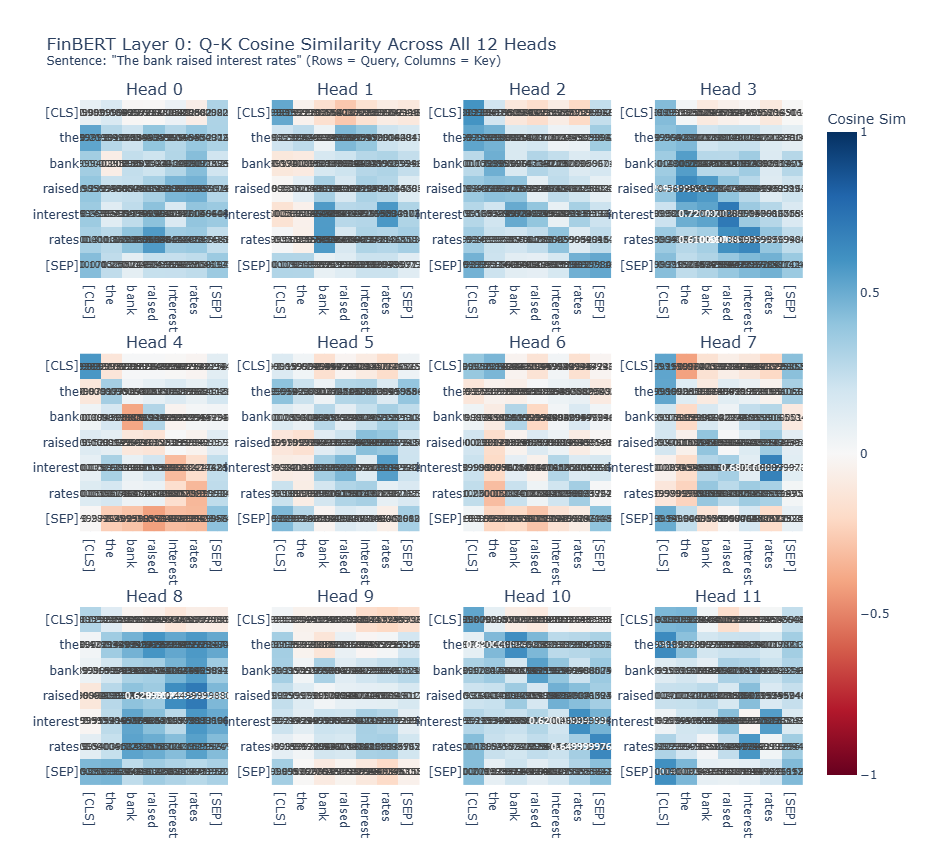

In [17]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import torch
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# 1. Load FinBERT & Tokenize
model_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

sentence = "The bank raised interest rates"
layer_idx = 0  # Change from 0 to 11 to inspect deeper layers

inputs = tokenizer(sentence, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
seq_len = len(tokens)

with torch.no_grad():
  # Extract hidden states entering the selected layer: [seq_len, 768]
  outputs = model(**inputs, output_hidden_states=True)
  X = outputs.hidden_states[layer_idx][0]

  # Project X into Q and K for all 12 heads
  attn_self = model.bert.encoder.layer[layer_idx].attention.self
  Q_all = attn_self.query(X)  # [seq_len, 768]
  K_all = attn_self.key(X)  # [seq_len, 768]

  # Reshape to [12 heads, seq_len, 64 dims]
  Q_heads = Q_all.view(seq_len, 12, 64).permute(1, 0, 2)
  K_heads = K_all.view(seq_len, 12, 64).permute(1, 0, 2)

  # Normalize Q and K along the 64-dim axis (L2 norm = 1)
  Q_norm = F.normalize(Q_heads, p=2, dim=-1)
  K_norm = F.normalize(K_heads, p=2, dim=-1)

  # Cosine Similarity Matrix for all 12 heads: [12, seq_len, seq_len]
  cos_sim_all = torch.matmul(Q_norm, K_norm.transpose(-1, -2)).numpy()

# 2. Build Interactive 3x4 Grid of Heatmaps with Plotly
fig = make_subplots(
    rows=3,
    cols=4,
    subplot_titles=[f"Head {h}" for h in range(12)],
    horizontal_spacing=0.06,
    vertical_spacing=0.11,
)

for h in range(12):
  row = (h // 4) + 1
  col = (h % 4) + 1
  sim_matrix = cos_sim_all[h]

  fig.add_trace(
      go.Heatmap(
          z=sim_matrix,
          x=tokens,  # Key tokens (columns)
          y=tokens,  # Query tokens (rows)
          colorscale="RdBu",  # Red = negative alignment, Blue = positive alignment
          zmin=-1.0,
          zmax=1.0,
          text=sim_matrix.round(2),
          texttemplate="%{text}",
          textfont={"size": 9},
          showscale=(h == 3),  # Show single colorbar on top-right
          colorbar=dict(title="Cosine Sim", x=1.02),
          hovertemplate=(
              f"<b>Head {h}</b><br>"
              "Query (row): <b>%{y}</b><br>"
              "Key (col): <b>%{x}</b><br>"
              "Cosine Similarity: <b>%{z:.4f}</b><extra></extra>"
          ),
      ),
      row=row,
      col=col,
  )
  # Flip Y-axis so [CLS] is at the top-left of each matrix
  fig.update_yaxes(autorange="reversed", row=row, col=col)

fig.update_layout(
    title=(
        f"FinBERT Layer {layer_idx}: Q-K Cosine Similarity Across All 12"
        f' Heads<br><sup>Sentence: "{sentence}" (Rows = Query, Columns ='
        " Key)</sup>"
    ),
    height=850,
    width=1150,
    template="plotly_white",
)

# Optional: Save as standalone interactive HTML file too
fig.write_html("finbert_qkv_cosine_similarity.html")

# Render directly inside Jupyter Notebook
fig.show()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

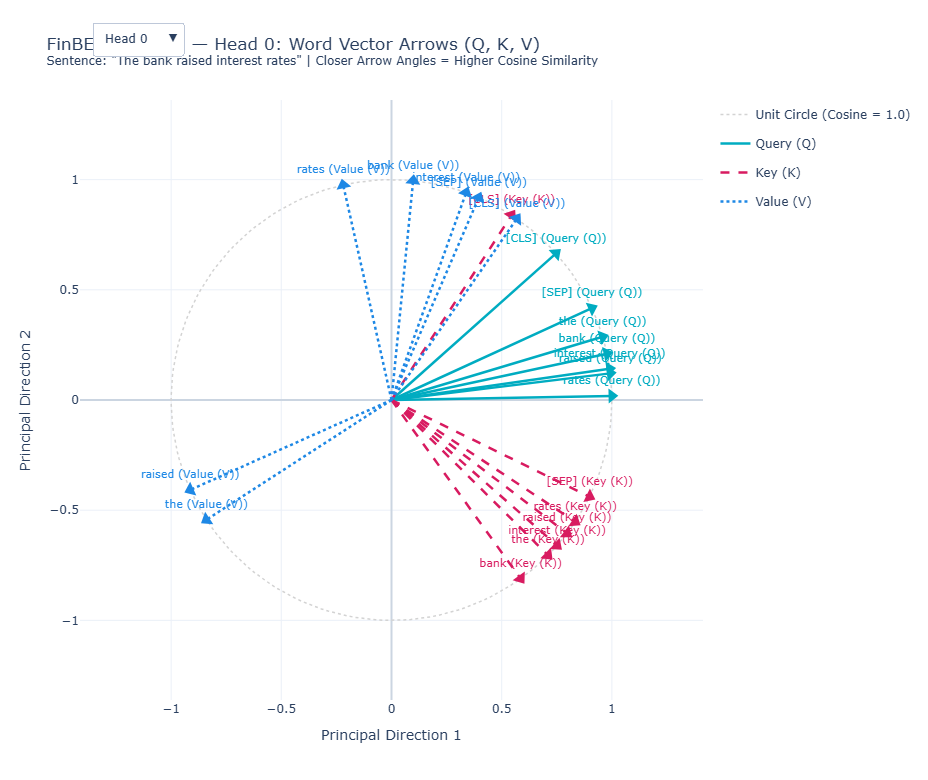

In [20]:
import numpy as np
import plotly.graph_objects as go
import torch
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# 1. Load FinBERT & Extract Q, K, V Tensors
model_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

sentence = "The bank raised interest rates"
layer_idx = 0  # Choose layer 0..11

inputs = tokenizer(sentence, return_tensors="pt")
input_ids_1d = inputs["input_ids"].squeeze(0).tolist()
tokens = tokenizer.convert_ids_to_tokens(input_ids_1d)
seq_len = len(tokens)

with torch.no_grad():
  outputs = model(**inputs, output_hidden_states=True)
  X = outputs.hidden_states[layer_idx].squeeze(0)  # Shape: (seq_len, 768)

  attn_self = model.bert.encoder.layer[layer_idx].attention.self
  Q_heads = attn_self.query(X).view(seq_len, 12, 64).permute(1, 0, 2)
  K_heads = attn_self.key(X).view(seq_len, 12, 64).permute(1, 0, 2)
  V_heads = attn_self.value(X).view(seq_len, 12, 64).permute(1, 0, 2)

  # Normalize to unit vectors so arrow angles directly reflect Cosine Similarity
  Q_norm = F.normalize(Q_heads, p=2, dim=-1).numpy()
  K_norm = F.normalize(K_heads, p=2, dim=-1).numpy()
  V_norm = F.normalize(V_heads, p=2, dim=-1).numpy()


# Helper: Project 64-dim vectors to 2D using SVD/PCA while preserving angles
def project_to_2d(q_mat, k_mat, v_mat):
  combined = np.vstack([q_mat, k_mat, v_mat])  # Shape: (3 * seq_len, 64)
  _, _, Vt = np.linalg.svd(combined, full_matrices=False)
  basis = Vt[:2].T  # Shape: (64, 2)
  q_2d = q_mat @ basis
  k_2d = k_mat @ basis
  v_2d = v_mat @ basis
  # Re-normalize in 2D so every arrow sits cleanly on the unit circle
  q_2d /= np.linalg.norm(q_2d, axis=1, keepdims=True) + 1e-8
  k_2d /= np.linalg.norm(k_2d, axis=1, keepdims=True) + 1e-8
  v_2d /= np.linalg.norm(v_2d, axis=1, keepdims=True) + 1e-8
  return q_2d, k_2d, v_2d


# 2. Build Interactive Plotly Figure with Arrows for All 12 Heads
fig = go.Figure()

# Draw Unit Reference Circle
theta = np.linspace(0, 2 * np.pi, 200)
fig.add_trace(
    go.Scatter(
        x=np.cos(theta),
        y=np.sin(theta),
        mode="lines",
        line=dict(color="lightgray", dash="dot", width=1.5),
        name="Unit Circle (Cosine = 1.0)",
        hoverinfo="skip",
    )
)

# Color palette for Q, K, V
styles = {
    "Query (Q)": {"color": "#00ACC1", "dash": "solid"},
    "Key (K)": {"color": "#D81B60", "dash": "dash"},
    "Value (V)": {"color": "#1E88E5", "dash": "dot"},
}

traces_per_head = 6  # 3 line traces + 3 arrowhead marker traces per head

for h in range(12):
  q2d, k2d, v2d = project_to_2d(Q_norm[h], K_norm[h], V_norm[h])
  visible = h == 0  # Show Head 0 by default

  for label, coords in [("Query (Q)", q2d), ("Key (K)", k2d), ("Value (V)", v2d)]:
    # Build line segments from (0,0) -> (x,y) separated by None
    lx, ly = [], []
    for x, y in coords:
      lx.extend([0, x, None])
      ly.extend([0, y, None])

    # Arrow shafts
    fig.add_trace(
        go.Scatter(
            x=lx,
            y=ly,
            mode="lines",
            line=dict(
                color=styles[label]["color"], width=2.5, dash=styles[label]["dash"]
            ),
            name=label,
            legendgroup=label,
            visible=visible,
            hoverinfo="skip",
        )
    )

    # Arrowheads + Word Labels at tips
    angles_deg = np.degrees(np.arctan2(coords[:, 0], coords[:, 1]))
    fig.add_trace(
        go.Scatter(
            x=coords[:, 0],
            y=coords[:, 1],
            mode="markers+text",
            marker=dict(
                symbol="triangle-up",
                size=13,
                angle=angles_deg,
                color=styles[label]["color"],
            ),
            text=[f"{tok} ({label})" for tok in tokens],
            textposition="top center",
            textfont=dict(size=11, color=styles[label]["color"]),
            name=label,
            legendgroup=label,
            showlegend=False,
            visible=visible,
            hovertemplate=(
                f"<b>Head {h} — {label}</b><br>"
                "Word: <b>%{text}</b><br>"
                "2D Direction: (%{x:.2f}, %{y:.2f})<extra></extra>"
            ),
        )
    )

# 3. Add Dropdown Menu to Switch Between Head 0 and Head 11
buttons = []
for h in range(12):
  vis_mask = [True] + [False] * (12 * traces_per_head)  # Keep unit circle visible
  start = 1 + h * traces_per_head
  for idx in range(start, start + traces_per_head):
    vis_mask[idx] = True

  buttons.append(
      dict(
          label=f"Head {h}",
          method="update",
          args=[
              {"visible": vis_mask},
              {
                  "title": (
                      f"FinBERT Layer {layer_idx} — Head {h}: Word Vector"
                      f' Arrows (Q, K, V)<br><sup>Sentence: "{sentence}" |'
                      " Closer Arrow Angles = Higher Cosine Similarity</sup>"
                  )
              },
          ],
      )
  )

fig.update_layout(
    title=(
        f"FinBERT Layer {layer_idx} — Head 0: Word Vector Arrows (Q, K,"
        f' V)<br><sup>Sentence: "{sentence}" | Closer Arrow Angles = Higher'
        " Cosine Similarity</sup>"
    ),
    updatemenus=[
        dict(
            active=0,
            buttons=buttons,
            x=0.02,
            y=1.13,
            xanchor="left",
            yanchor="top",
        )
    ],
    xaxis=dict(
        range=[-1.35, 1.35],
        zeroline=True,
        zerolinecolor="#cbd5e1",
        showgrid=True,
        title="Principal Direction 1",
    ),
    yaxis=dict(
        range=[-1.35, 1.35],
        zeroline=True,
        zerolinecolor="#cbd5e1",
        showgrid=True,
        scaleanchor="x",
        scaleratio=1,
        title="Principal Direction 2",
    ),
    width=900,
    height=780,
    template="plotly_white",
)

fig.write_html("finbert_qkv_vector_arrows.html")
fig.show()
